<a href="https://colab.research.google.com/github/fitridianamusa/Artikel-ADW-Kelompok-8/blob/main/Tugas_Kelompok_8_ARIMA_Python.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tugas Kelompok 8 — Pendugaan Parameter ARIMA

**Model:** ARIMA(1,0,2) dan ARIMA(2,1,2)  
**Metode:** Kuadrat Terkecil Bersyarat (CSS) dan Kemungkinan Maksimum (ML)  
**Seed:** 2513  
**Jumlah ulangan:** 30  
**Panjang deret:** 200 pengamatan

Notebook ini menggunakan Python. Estimasi ML dilakukan dengan `statsmodels`. Estimasi CSS dihitung dengan meminimumkan jumlah kuadrat residual bersyarat menggunakan `scipy.optimize`.

**Konvensi model:**  
\(y_t = \phi_1 y_{t-1} + \cdots + e_t + \theta_1 e_{t-1} + \cdots\).  
Untuk ARIMA(2,1,2), AR dan MA diterapkan pada deret yang telah didifferencing satu kali, kemudian data level dibentuk dengan penjumlahan kumulatif.

Catatan: estimasi CSS dan ML dapat memakai perlakuan inisialisasi residual yang berbeda. Karena itu, hasilnya mungkin tidak persis sama dengan perangkat lunak lain yang menerapkan CSS secara berbeda.


In [1]:
# Jika paket belum tersedia, jalankan baris berikut:
%pip install numpy pandas matplotlib scipy statsmodels


In [30]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.optimize import minimize
from statsmodels.tsa.arima.model import ARIMA

warnings.filterwarnings("ignore")

SEED = 2513
N = 100
B = 30

# Parameter asli yang digunakan untuk membangkitkan data
PARAMETERS = {
    "ARIMA(1,0,2)": {"ar": np.array([0.5]), "ma": np.array([0.4, 0.3]), "d": 0},
    "ARIMA(2,1,2)": {"ar": np.array([0.5, -0.2]), "ma": np.array([0.4, 0.3]), "d": 1},
}

print("Konfigurasi:")
print(f"Seed = {SEED}, panjang deret = {N}, jumlah ulangan = {B}")


Konfigurasi:
Seed = 2513, panjang deret = 100, jumlah ulangan = 30


## 1. Fungsi simulasi

Fungsi berikut membangkitkan proses ARMA dengan rekursi residual, lalu untuk ARIMA(2,1,2) mengintegrasikan proses dengan `cumsum`. Seed ditetapkan satu kali sebelum seluruh simulasi agar 30 ulangan menghasilkan deret yang berbeda tetapi dapat direproduksi.


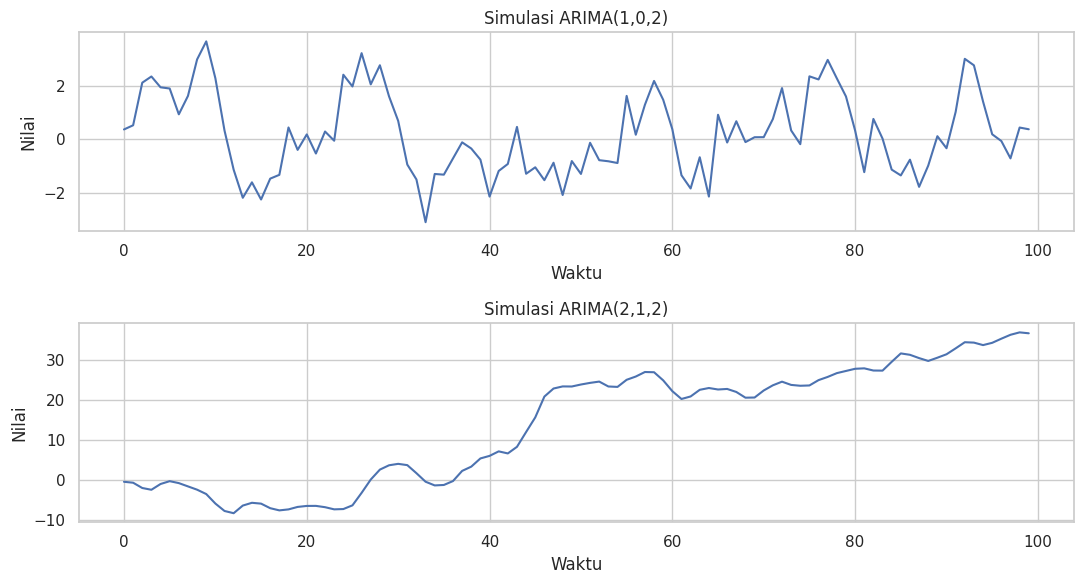

In [31]:
def simulate_arma(n, ar, ma, rng, burnin=300):
    """Simulasi ARMA(p,q): y[t] = sum(phi*y_lag) + e[t] + sum(theta*e_lag)."""
    p, q = len(ar), len(ma)
    total = n + burnin
    eps = rng.normal(0, 1, total)
    y = np.zeros(total)

    for t in range(total):
        ar_part = 0.0
        for j in range(1, p + 1):
            if t - j >= 0:
                ar_part += ar[j - 1] * y[t - j]

        ma_part = 0.0
        for j in range(1, q + 1):
            if t - j >= 0:
                ma_part += ma[j - 1] * eps[t - j]

        y[t] = ar_part + eps[t] + ma_part

    return y[burnin:]


def simulate_arima_102(n, rng):
    return simulate_arma(
        n=n,
        ar=PARAMETERS["ARIMA(1,0,2)"]["ar"],
        ma=PARAMETERS["ARIMA(1,0,2)"]["ma"],
        rng=rng
    )


def simulate_arima_212(n, rng):
    # Bangkitkan proses ARMA(2,2) untuk differenced series, lalu integrasikan.
    diff_series = simulate_arma(
        n=n,
        ar=PARAMETERS["ARIMA(2,1,2)"]["ar"],
        ma=PARAMETERS["ARIMA(2,1,2)"]["ma"],
        rng=rng
    )
    return np.cumsum(diff_series)


# Contoh satu simulasi untuk masing-masing model
rng_demo = np.random.default_rng(SEED)
demo_102 = simulate_arima_102(N, rng_demo)
demo_212 = simulate_arima_212(N, rng_demo)

fig, axes = plt.subplots(2, 1, figsize=(11, 6))
axes[0].plot(demo_102)
axes[0].set_title("Simulasi ARIMA(1,0,2)")
axes[0].set_xlabel("Waktu")
axes[0].set_ylabel("Nilai")
axes[1].plot(demo_212)
axes[1].set_title("Simulasi ARIMA(2,1,2)")
axes[1].set_xlabel("Waktu")
axes[1].set_ylabel("Nilai")
plt.tight_layout()
plt.show()


## 2. Fungsi estimasi CSS dan ML

- **CSS (Conditional Sum of Squares):** meminimumkan jumlah kuadrat residual bersyarat. Residual awal ditetapkan nol dan beberapa residual awal tidak dimasukkan ke jumlah kuadrat.
- **ML (Maximum Likelihood):** menggunakan estimasi likelihood berbasis state space dari `statsmodels`.

Untuk ARIMA(1,0,2), konstanta/rata-rata tidak dimasukkan karena proses pembangkit memiliki rata-rata nol. Untuk ARIMA(2,1,2), model differenced tidak memasukkan drift.


In [32]:
def conditional_residuals(y, ar, ma):
    """Residual rekursif untuk model ARMA tanpa konstanta."""
    y = np.asarray(y, dtype=float)
    p, q = len(ar), len(ma)
    e = np.zeros(len(y))

    for t in range(len(y)):
        ar_part = sum(ar[j - 1] * y[t - j] for j in range(1, p + 1) if t - j >= 0)
        ma_part = sum(ma[j - 1] * e[t - j] for j in range(1, q + 1) if t - j >= 0)
        e[t] = y[t] - ar_part - ma_part

    return e


def fit_css(y, p, d, q):
    """Estimasi CSS dengan meminimumkan jumlah kuadrat residual pada series yang sesuai."""
    y = np.asarray(y, dtype=float)
    yd = np.diff(y, n=d) if d > 0 else y.copy()

    # Inisialisasi koefisien nol; parameter berurutan: AR kemudian MA.
    x0 = np.zeros(p + q)
    burn = max(p, q)

    def objective(params):
        ar = params[:p]
        ma = params[p:]
        resid = conditional_residuals(yd, ar, ma)
        use = resid[burn:] if len(resid) > burn else resid
        value = np.sum(use ** 2)
        return value if np.isfinite(value) else 1e100

    # Batas longgar membantu mencegah optimasi menuju koefisien ekstrem.
    bounds = [(-0.98, 0.98)] * (p + q)
    result = minimize(objective, x0=x0, method="L-BFGS-B", bounds=bounds)

    if not result.success and not np.isfinite(result.fun):
        raise RuntimeError("Optimasi CSS gagal.")

    params = result.x
    names = [f"ar{i}" for i in range(1, p + 1)] + [f"ma{i}" for i in range(1, q + 1)]
    return pd.Series(params, index=names)


def fit_ml(y, p, d, q):
    """Estimasi ML ARIMA melalui statsmodels."""
    model = ARIMA(
        np.asarray(y, dtype=float),
        order=(p, d, q),
        trend="n"
    )
    fitted = model.fit()

    # Ambil hanya koefisien AR dan MA; tidak menyertakan varians inovasi.
    out = {}
    for i in range(1, p + 1):
        out[f"ar{i}"] = fitted.params[list(fitted.param_names).index(f"ar.L{i}")]
    for i in range(1, q + 1):
        out[f"ma{i}"] = fitted.params[list(fitted.param_names).index(f"ma.L{i}")]
    return pd.Series(out)


## 3. Estimasi pada satu simulasi

Bagian ini menampilkan contoh pendugaan satu kali untuk setiap model dengan CSS dan ML. Hasil satu simulasi belum cukup untuk menyimpulkan metode mana yang lebih baik; evaluasi utama dilakukan berdasarkan 30 ulangan.


In [33]:
# Contoh estimasi pada data simulasi
example_rng = np.random.default_rng(SEED)
x102 = simulate_arima_102(N, example_rng)
x212 = simulate_arima_212(N, example_rng)

example_results = []

for model_name, y, p, d, q in [
    ("ARIMA(1,0,2)", x102, 1, 0, 2),
    ("ARIMA(2,1,2)", x212, 2, 1, 2),
]:
    for method, fit_func in [("CSS", fit_css), ("ML", fit_ml)]:
        estimates = fit_func(y, p, d, q)
        for parameter, estimate in estimates.items():
            example_results.append({
                "Model": model_name,
                "Metode": method,
                "Parameter": parameter,
                "Dugaan": estimate
            })

pd.DataFrame(example_results)


,Model,Metode,Parameter,Dugaan
0,"ARIMA(1,0,2)",CSS,ar1,0.586679
1,"ARIMA(1,0,2)",CSS,ma1,0.120431
2,"ARIMA(1,0,2)",CSS,ma2,0.291760
3,"ARIMA(1,0,2)",ML,ar1,0.579232
4,"ARIMA(1,0,2)",ML,ma1,0.122301
5,"ARIMA(1,0,2)",ML,ma2,0.288014
6,"ARIMA(2,1,2)",CSS,ar1,0.528599
7,"ARIMA(2,1,2)",CSS,ar2,-0.255109
8,"ARIMA(2,1,2)",CSS,ma1,0.365049
9,"ARIMA(2,1,2)",CSS,ma2,0.332111


## 4. Mengulang simulasi sebanyak 30 kali

Seed 2513 dipakai untuk menginisialisasi generator bilangan acak sekali. Setiap ulangan menghasilkan data baru. Pada ulangan yang sama, CSS dan ML diterapkan pada deret simulasi yang sama agar perbandingan adil.


In [34]:
rng = np.random.default_rng(SEED)
records = []
failed_fits = []

for rep in range(1, B + 1):
    # Data baru pada setiap ulangan
    y102 = simulate_arima_102(N, rng)
    y212 = simulate_arima_212(N, rng)

    simulations = [
        ("ARIMA(1,0,2)", y102, 1, 0, 2, PARAMETERS["ARIMA(1,0,2)"]),
        ("ARIMA(2,1,2)", y212, 2, 1, 2, PARAMETERS["ARIMA(2,1,2)"]),
    ]

    for model_name, y, p, d, q, true_pars in simulations:
        true_values = {
            **{f"ar{i+1}": val for i, val in enumerate(true_pars["ar"])},
            **{f"ma{i+1}": val for i, val in enumerate(true_pars["ma"])},
        }

        for method, fit_func in [("CSS", fit_css), ("ML", fit_ml)]:
            try:
                estimates = fit_func(y, p, d, q)
                for parameter, true_value in true_values.items():
                    estimate = float(estimates[parameter])
                    records.append({
                        "Ulangan": rep,
                        "Model": model_name,
                        "Metode": method,
                        "Parameter": parameter,
                        "Asli": float(true_value),
                        "Dugaan": estimate,
                        "Error": estimate - float(true_value)
                    })
            except Exception as exc:
                failed_fits.append({
                    "Ulangan": rep,
                    "Model": model_name,
                    "Metode": method,
                    "Error": str(exc)
                })

hasil = pd.DataFrame(records)

print("Jumlah pendugaan yang berhasil:", len(hasil))
print("Jumlah proses estimasi yang gagal:", len(failed_fits))
if failed_fits:
    display(pd.DataFrame(failed_fits))

display(hasil.head(10))


Jumlah pendugaan yang berhasil: 420
Jumlah proses estimasi yang gagal: 0


,Ulangan,Model,Metode,Parameter,Asli,Dugaan,Error
0,1,"ARIMA(1,0,2)",CSS,ar1,0.5,0.586679,0.086679
1,1,"ARIMA(1,0,2)",CSS,ma1,0.4,0.120431,-0.279569
2,1,"ARIMA(1,0,2)",CSS,ma2,0.3,0.291760,-0.008240
3,1,"ARIMA(1,0,2)",ML,ar1,0.5,0.579232,0.079232
4,1,"ARIMA(1,0,2)",ML,ma1,0.4,0.122301,-0.277699
5,1,"ARIMA(1,0,2)",ML,ma2,0.3,0.288014,-0.011986
6,1,"ARIMA(2,1,2)",CSS,ar1,0.5,0.528599,0.028599
7,1,"ARIMA(2,1,2)",CSS,ar2,-0.2,-0.255109,-0.055109
8,1,"ARIMA(2,1,2)",CSS,ma1,0.4,0.365049,-0.034951
9,1,"ARIMA(2,1,2)",CSS,ma2,0.3,0.332111,0.032111


## 5. Menghitung bias dan ragam

Bias empiris dihitung sebagai rata-rata pendugaan dikurangi parameter sebenarnya. Ragam dihitung menggunakan ragam sampel (`ddof=1`) dari pendugaan yang berhasil.

\[
\widehat{Bias}(\hat\theta)=\frac{1}{B}\sum_{i=1}^{B}\hat\theta_i-\theta
\]

\[
\widehat{Var}(\hat\theta)=\frac{1}{B-1}\sum_{i=1}^{B}(\hat\theta_i-\bar{\hat\theta})^2
\]

Jika ada proses estimasi gagal, jumlah pendugaan valid untuk suatu kombinasi bisa kurang dari 30. Periksa kolom `Jumlah_valid` sebelum menafsirkan hasil.


In [35]:
ringkasan = (
    hasil.groupby(["Model", "Metode", "Parameter"], as_index=False)
    .agg(
        Jumlah_valid=("Dugaan", "count"),
        Parameter_asli=("Asli", "first"),
        Rata_rata_dugaan=("Dugaan", "mean"),
        Bias=("Error", "mean"),
        Ragam=("Dugaan", lambda x: x.var(ddof=1))
    )
)

display(ringkasan.round(5))


,Model,Metode,Parameter,Jumlah_valid,Parameter_asli,Rata_rata_dugaan,Bias,Ragam
0,"ARIMA(1,0,2)",CSS,ar1,30,0.5,0.51886,0.01886,0.01343
1,"ARIMA(1,0,2)",CSS,ma1,30,0.4,0.37245,-0.02755,0.01668
2,"ARIMA(1,0,2)",CSS,ma2,30,0.3,0.27219,-0.02781,0.02864
3,"ARIMA(1,0,2)",ML,ar1,30,0.5,0.51877,0.01877,0.01315
4,"ARIMA(1,0,2)",ML,ma1,30,0.4,0.37198,-0.02802,0.01689
5,"ARIMA(1,0,2)",ML,ma2,30,0.3,0.27224,-0.02776,0.02796
6,"ARIMA(2,1,2)",CSS,ar1,30,0.5,0.53989,0.03989,0.09966
7,"ARIMA(2,1,2)",CSS,ar2,30,-0.2,-0.26570,-0.06570,0.03028
8,"ARIMA(2,1,2)",CSS,ma1,30,0.4,0.34570,-0.05430,0.09724
9,"ARIMA(2,1,2)",CSS,ma2,30,0.3,0.35282,0.05282,0.04060


## 6. Boxplot galat pendugaan

Galat didefinisikan sebagai `Dugaan - Asli`. Garis horizontal nol menjadi acuan:
- median dekat nol menunjukkan kecenderungan galat yang kecil;
- kotak lebih sempit menunjukkan sebaran 50% galat tengah lebih kecil;
- pencilan menunjukkan ulangan dengan galat yang relatif jauh dari mayoritas.

Boxplot tidak memberikan satu angka ragam secara langsung. Gunakan tabel bias dan ragam di bagian sebelumnya untuk perbandingan numerik.


## 7. Interpretasi hasil

Gunakan hasil tabel dan boxplot yang benar-benar muncul setelah notebook dijalankan.

1. **Bias:** metode dengan nilai absolut bias lebih dekat ke nol memiliki bias empiris yang lebih kecil.
2. **Ragam:** metode dengan ragam pendugaan lebih kecil menghasilkan estimasi yang lebih konsisten antarulangan.
3. **Boxplot:** perhatikan median galat terhadap garis nol, lebar kotak, panjang whisker, dan pencilan.
4. **Perbandingan model:** simpulkan untuk tiap parameter secara terpisah; jangan menganggap CSS atau ML selalu unggul pada semua parameter.
5. **Keterbatasan:** 30 ulangan memberi gambaran empiris, tetapi ringkasan bias dan ragam masih dapat berubah jika simulasi diulang dengan seed lain atau jumlah ulangan diperbesar.

**Catatan teknis:** implementasi CSS di notebook ini adalah optimasi jumlah kuadrat residual bersyarat dengan residual awal nol. Ini adalah implementasi CSS yang eksplisit, tetapi tidak harus identik dengan algoritme CSS pada semua paket statistik.


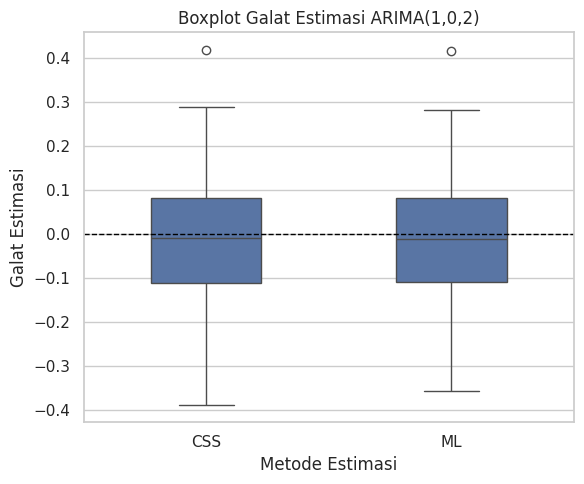

In [45]:
import matplotlib.pyplot as plt
import seaborn as sns

data_plot = hasil[hasil["Model"] == "ARIMA(1,0,2)"].copy()

plt.figure(figsize=(6, 5))

sns.boxplot(
    data=data_plot,
    x="Metode",
    y="Error",
    order=["CSS", "ML"],
    width=0.45
)

plt.axhline(0, color="black", linestyle="--", linewidth=1)
plt.title("Boxplot Galat Estimasi ARIMA(1,0,2)")
plt.xlabel("Metode Estimasi")
plt.ylabel("Galat Estimasi")
plt.tight_layout()
plt.show()

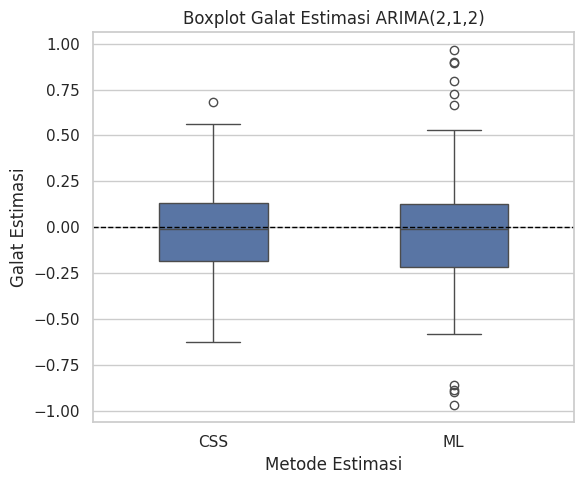

In [46]:
data_plot = hasil[hasil["Model"] == "ARIMA(2,1,2)"].copy()

plt.figure(figsize=(6, 5))

sns.boxplot(
    data=data_plot,
    x="Metode",
    y="Error",
    order=["CSS", "ML"],
    width=0.45
)

plt.axhline(0, color="black", linestyle="--", linewidth=1)
plt.title("Boxplot Galat Estimasi ARIMA(2,1,2)")
plt.xlabel("Metode Estimasi")
plt.ylabel("Galat Estimasi")
plt.tight_layout()
plt.show()

In [47]:
import pandas as pd

# Ambil data ARIMA(2,1,2) dengan metode ML
data_ml = hasil[
    (hasil["Model"] == "ARIMA(2,1,2)") &
    (hasil["Metode"] == "ML")
].copy()

# Hitung batas outlier
Q1 = data_ml["Error"].quantile(0.25)
Q3 = data_ml["Error"].quantile(0.75)
IQR = Q3 - Q1

batas_bawah = Q1 - 1.5 * IQR
batas_atas = Q3 + 1.5 * IQR

# Identifikasi outlier
outlier = data_ml[
    (data_ml["Error"] < batas_bawah) |
    (data_ml["Error"] > batas_atas)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Batas bawah:", batas_bawah)
print("Batas atas:", batas_atas)

print("\nGalat estimasi yang menjadi outlier:")
print(outlier)

Q1: -0.2156594230555136
Q3: 0.12362663577790803
IQR: 0.33928605883342167
Batas bawah: -0.724588511305646
Batas atas: 0.6325557240280405

Galat estimasi yang menjadi outlier:
     Ulangan         Model Metode Parameter  Asli    Dugaan     Error
24         2  ARIMA(2,1,2)     ML       ar1   0.5 -0.361318 -0.861318
25         2  ARIMA(2,1,2)     ML       ar2  -0.2  0.596860  0.796860
26         2  ARIMA(2,1,2)     ML       ma1   0.4  1.365572  0.965572
66         5  ARIMA(2,1,2)     ML       ar1   0.5  1.396496  0.896496
68         5  ARIMA(2,1,2)     ML       ma1   0.4 -0.566852 -0.966852
111        8  ARIMA(2,1,2)     ML       ma2   0.3  0.966265  0.666265
150       11  ARIMA(2,1,2)     ML       ar1   0.5  1.228232  0.728232
152       11  ARIMA(2,1,2)     ML       ma1   0.4 -0.488560 -0.888560
346       25  ARIMA(2,1,2)     ML       ar1   0.5  1.403091  0.903091
348       25  ARIMA(2,1,2)     ML       ma1   0.4 -0.498593 -0.898593
